# C3: Dense Layers and Activation Functions

## 1. Introduction
In this notebook, we dive deep into the fundamental building blocks of Deep Learning: **Dense Layers** and **Activation Functions**. 

We will explore:
- **Neural Networks**: How neurons, weights, and biases work mathematically.
- **Dense Layers**: Implementing them from scratch (low-level) and using Keras (high-level).
- **Activation Functions**: The magic that adds non-linearity (Sigmoid, ReLU, Softmax).
- **Weight Initialization**: How to properly initialize neural network weights.
- **Building Simple Networks**: Putting layers together to create a classifier.

---


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Ensure reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")

/opt/anaconda3/envs/tensorflow_env/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


TensorFlow Version: 2.16.1


## 2. Dense Layers (The Math)

A **Dense Layer** (or Fully Connected Layer) performs a linear operation. Each neuron in the layer receives input from all neurons in the previous layer.

### Formula
$$ \text{output} = \text{activation}(\text{dot}(\text{input}, \text{kernel}) + \text{bias}) $$

Or simply:
$$ y = Wx + b $$

Where:
- $x$ is the input vector.
- $W$ (kernel) is the weight matrix.
- $b$ is the bias vector.

### Diagram
The output is a weighted sum of inputs plus a bias.

![Perceptron Diagram](https://upload.wikimedia.org/wikipedia/commons/thumb/6/60/ArtificialNeuronModel_english.png/600px-ArtificialNeuronModel_english.png)
*(Source: Wikipedia)*

### 2.1 Low-Level Implementation (From Scratch)
Let's implement a single Dense layer using TensorFlow's basic operations (`tf.matmul`, `tf.add`).

In [2]:
# Input data: 1 sample with 2 features (e.g., [sqft, bedrooms])
# Shape: (1, 2)
inputs = tf.constant([[1.0, 35.0]])

# Weights (Kernel): 2 inputs -> 1 output neuron
# Shape: (2, 1)
weights = tf.Variable([[-0.05], [-0.01]])

# Bias: 1 output neuron
# Shape: (1,)
bias = tf.Variable([0.5])

# Linear Operation: y = Wx + b
# Matrix multiplication matches dimensions: (1,2) * (2,1) -> (1,1)
product = tf.matmul(inputs, weights)
dense_output = tf.add(product, bias)

print("Inputs:", inputs.numpy())
print("Weights:", weights.numpy())
print("Bias:", bias.numpy())
print("Output (Low-level):", dense_output.numpy())

Inputs: [[ 1. 35.]]
Weights: [[-0.05]
 [-0.01]]
Bias: [0.5]
Output (Low-level): [[0.09999999]]


2026-01-04 13:29:59.369564: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Max
2026-01-04 13:29:59.369589: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-01-04 13:29:59.369596: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-01-04 13:29:59.369614: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-01-04 13:29:59.369625: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


### 2.2 High-Level Implementation (Keras)
In practice, we use `tf.keras.layers.Dense`. It handles the creation of weights (`kernel`) and biases (`bias`) automatically.

In [3]:
# Create a Dense layer with 1 neuron
dense_layer = tf.keras.layers.Dense(units=1)

# Pass input to initialize weights
output_keras = dense_layer(inputs)

# Inspect the automatically created weights
print("Keras Output:", output_keras.numpy())
print("\nKeras Kernel (Weights):\n", dense_layer.kernel.numpy())
print("Keras Bias:\n", dense_layer.bias.numpy())

Keras Output: [[32.502167]]

Keras Kernel (Weights):
 [[-1.001374  ]
 [ 0.95724404]]
Keras Bias:
 [0.]


## 3. Activation Functions

Without activation functions, a neural network—no matter how many layers it has—is just a **single Linear Regression model**. 

> **Why?** Because a linear combination of linear functions is still just a linear function.

Activation functions introduce **non-linearity**, allowing the network to learn complex curves and patterns.

### Comparison of Common Activations

| Function | Range | Use Case | Pros | Cons |
| :--- | :--- | :--- | :--- | :--- |
| **Sigmoid** | (0, 1) | Binary Classification (Output) | Probabilistic interpretation | Vanishing gradient problem |
| **ReLU** | [0, ∞) | Hidden Layers (Default) | Fast, solves vanishing gradient | Dead neurons (if inputs < 0) |
| **Softmax** | (0, 1) | Multi-class Classification (Output) | Probabilities sum to 1 | computationally expensive |

### Visualizing Activations

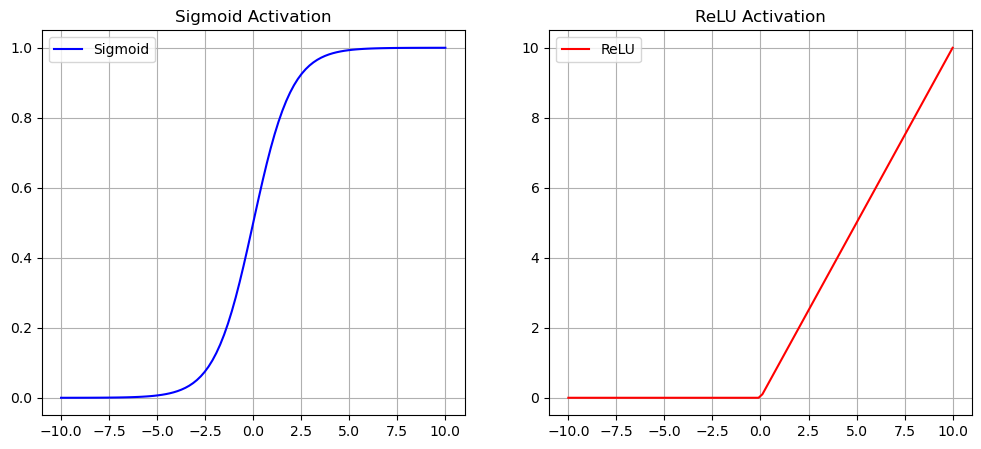

In [4]:
# Generate simple x data
x = tf.linspace(-10.0, 10.0, 100)

# Apply activation functions
y_sigmoid = tf.keras.activations.sigmoid(x)
y_relu = tf.keras.activations.relu(x)

# Plotting
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(x, y_sigmoid, label="Sigmoid", color='blue')
plt.title("Sigmoid Activation")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, y_relu, label="ReLU", color='red')
plt.title("ReLU Activation")
plt.grid(True)
plt.legend()

plt.show()

## 4. Weight Initialization

### Why Initialization Matters
How do we start? We can't initialize weights to **Zero**, or all neurons will learn the exact same thing (symmetry problem).

> [!IMPORTANT]
> **Best Practices:**
> - **He Initialization**: Best for ReLU layers.
> - **Glorot (Xavier) Initialization**: Best for Sigmoid/Tanh layers.

When building models, you'll specify the initialization strategy like this:
```python
tf.keras.layers.Dense(64, activation='relu', kernel_initializer='he_normal')
```

Later in the training modules, you'll learn about optimizers (algorithms that update weights during training). For now, know that `adam` is a good default choice for most problems.

## 5. Building a Simple Classification Model

Let's build a simple network to classify data using the components we've learned.

In [ ]:
# 1. Generate Dummy Data
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=1000, noise=0.03, factor=0.5, random_state=42)

# 2. Build Model
model = tf.keras.Sequential([
    # Input Layer implicitly defined by input_shape in first layer
    
    # Hidden Layer 1: Dense + ReLU + He Initialization
    tf.keras.layers.Dense(16, activation='relu', kernel_initializer='he_normal', input_shape=(2,)),
    
    # Hidden Layer 2
    tf.keras.layers.Dense(8, activation='relu', kernel_initializer='he_normal'),
    
    # Output Layer: Sigmoid for Binary Classification (0 or 1)
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# 3. Compile with Adam Optimizer
# Note: You'll learn about optimizers in detail in Module 03
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

In [ ]:
# 4. Train the model
history = model.fit(X, y, epochs=20, batch_size=32, verbose=1)

## 6. Exercises

1. **Manual Layer:** Create a Dense layer with 5 neurons using `tf.matmul`. Input shape should be `(1, 10)`.
2. **Activation Swap:** Change the activation in the model above to `tanh` and retrain. Does it perform better or worse?
3. **Layer Architecture:** Try building a deeper network with 3 hidden layers (32, 16, 8 neurons). How does it affect performance?
4. **Initialization Experiment:** Change the kernel_initializer from 'he_normal' to 'glorot_uniform'. Compare the results.